# Optimizacion de Logistic Regression
Buscamos los mejores hiperparametros para maximizar el accuracy en el test set.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

print('OK')

OK


In [2]:
# CARGAR Y PREPARAR DATOS (igual que antes)
df_ori   = pd.read_csv('../data/data_breast_cancer_red.csv')
df_train = df_ori[df_ori['diagnosis'].notna()].copy()
df_test  = df_ori[df_ori['diagnosis'].isna()].copy()

le = LabelEncoder()
if not pd.api.types.is_numeric_dtype(df_train['diagnosis']):
    df_train['diagnosis'] = le.fit_transform(df_train['diagnosis'])

drop_cols    = ['diagnosis'] + [c for c in ['id'] if c in df_ori.columns]
feature_cols = [c for c in df_ori.columns if c not in drop_cols]

X      = df_train[feature_cols].values
y      = df_train['diagnosis'].values
X_test = df_test[feature_cols].values

print(f'Train: {X.shape}, Test: {X_test.shape}')

Train: (319, 30), Test: (250, 30)


In [3]:
# PIPELINE: imputer -> scaler -> LR
# Usamos Pipeline para que el GridSearch no tenga data leakage:
# el scaler se ajusta SOLO con los datos de train de cada fold

pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
    ('lr',      LogisticRegression(max_iter=2000, random_state=42))
])

# GRIDSEARCH sobre los parametros mas importantes de LR
# Nota: en Pipeline, los parametros se nombran como 'paso__parametro'
param_grid = {
    'lr__C':       [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0],
    'lr__penalty': ['l1', 'l2'],       # l1=Lasso (fuerza zeros), l2=Ridge (suaviza)
    'lr__solver':  ['liblinear'],       # liblinear soporta tanto l1 como l2
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X, y)

print(f'\nMejores parametros: {grid_search.best_params_}')
print(f'Mejor CV accuracy:  {grid_search.best_score_:.4f}')

Fitting 10 folds for each of 18 candidates, totalling 180 fits



Mejores parametros: {'lr__C': 0.1, 'lr__penalty': 'l2', 'lr__solver': 'liblinear'}
Mejor CV accuracy:  0.9780


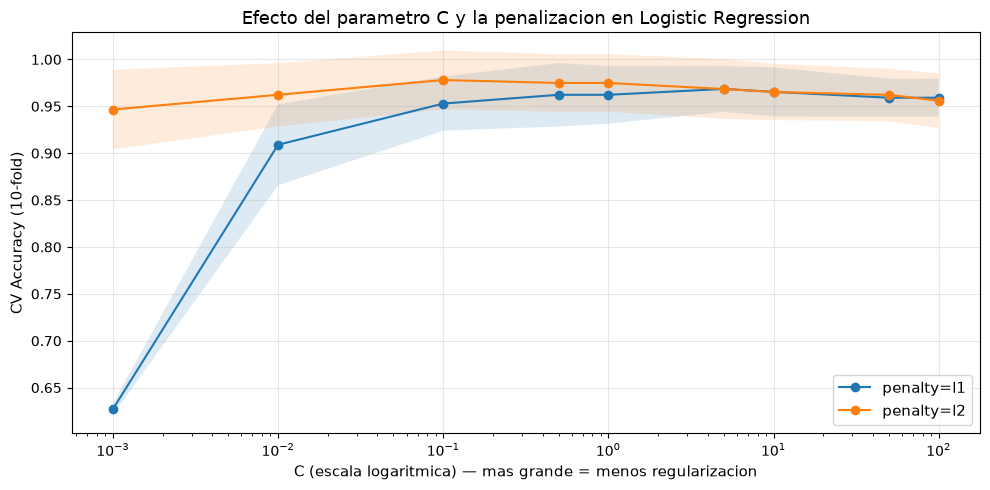

El area sombreada muestra +/- 1 desviacion estandar entre folds


In [4]:
# VISUALIZAR EL EFECTO DE C PARA CADA PENALTY
results_df = pd.DataFrame(grid_search.cv_results_)

fig, ax = plt.subplots(figsize=(10, 5))
C_values = [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0]

for penalty in ['l1', 'l2']:
    mask = (results_df['param_lr__penalty'] == penalty)
    subset = results_df[mask].sort_values('param_lr__C')
    ax.plot(
        subset['param_lr__C'].astype(float),
        subset['mean_test_score'],
        marker='o', label=f'penalty={penalty}'
    )
    ax.fill_between(
        subset['param_lr__C'].astype(float),
        subset['mean_test_score'] - subset['std_test_score'],
        subset['mean_test_score'] + subset['std_test_score'],
        alpha=0.15
    )

ax.set_xscale('log')
ax.set_xlabel('C (escala logaritmica) — mas grande = menos regularizacion', fontsize=11)
ax.set_ylabel('CV Accuracy (10-fold)', fontsize=11)
ax.set_title('Efecto del parametro C y la penalizacion en Logistic Regression', fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('El area sombreada muestra +/- 1 desviacion estandar entre folds')

In [5]:
# COMPARAR BASELINE vs OPTIMIZADO
baseline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
    ('lr',      LogisticRegression(C=1.0, max_iter=2000, random_state=42))
])
base_scores = cross_val_score(baseline, X, y, cv=cv, scoring='accuracy')

best_scores = cross_val_score(grid_search.best_estimator_, X, y, cv=cv, scoring='accuracy')

print(f'LR baseline (C=1.0):   mean={base_scores.mean():.4f}  std={base_scores.std():.4f}')
print(f'LR optimizado:         mean={best_scores.mean():.4f}  std={best_scores.std():.4f}')
mejora = (best_scores.mean() - base_scores.mean()) * 100
print(f'Mejora: +{mejora:.2f} puntos porcentuales')

LR baseline (C=1.0):   mean=0.9718  std=0.0295
LR optimizado:         mean=0.9780  std=0.0314
Mejora: +0.62 puntos porcentuales


In [6]:
import os
os.makedirs('../outputs', exist_ok=True)
OUT_PATH = '../outputs/predictions_logreg.csv'
# GENERAR PREDICCIONES CON EL MODELO OPTIMIZADO
best_model = grid_search.best_estimator_
best_model.fit(X, y)  # entrenar con TODO el train set

y_pred = best_model.predict(X_test)

if hasattr(le, 'classes_'):
    y_pred_labels = le.inverse_transform(y_pred) if hasattr(le, 'classes_') else y_pred
else:
    y_pred_labels = y_pred

id_col = df_test['id'] if 'id' in df_test.columns else df_test.index
df_pred = pd.DataFrame({'id': id_col, 'diagnosis': y_pred_labels})
df_pred.to_csv(OUT_PATH, index=False)

print(f'CSV generado con {len(df_pred)} predicciones')
print(df_pred['diagnosis'].value_counts())
df_pred.head(10)

CSV generado con 250 predicciones
diagnosis
B    159
M     91
Name: count, dtype: int64


,id,diagnosis
2,84300903,M
4,84358402,M
8,844981,M
9,84501001,M
10,845636,M
12,846226,M
14,84667401,M
15,84799002,M
16,848406,M
17,84862001,M


## Que hace cada hiperparametro

| Parametro | Que controla | Cuando usar cada valor |
|-----------|-------------|------------------------|
| **C pequeño** (0.001-0.1) | Mucha regularizacion: penaliza coeficientes grandes, modelo mas simple | Si hay overfitting o muchas features correladas |
| **C grande** (10-100) | Poca regularizacion: el modelo se ajusta mas a los datos de train | Si el dataset es limpio y hay suficientes muestras |
| **penalty=l2** (Ridge) | Reduce todos los coeficientes proporcionalmente, nunca los pone a cero | Default, funciona bien en la mayoria de casos |
| **penalty=l1** (Lasso) | Puede poner coeficientes exactamente a cero (seleccion de features implicita) | Cuando sospechas que algunas features son irrelevantes |

**Regla practica:** si l1 gana, significa que el modelo esta descartando algunas features automaticamente y eso ayuda. Si l2 gana, todas las features aportan algo.